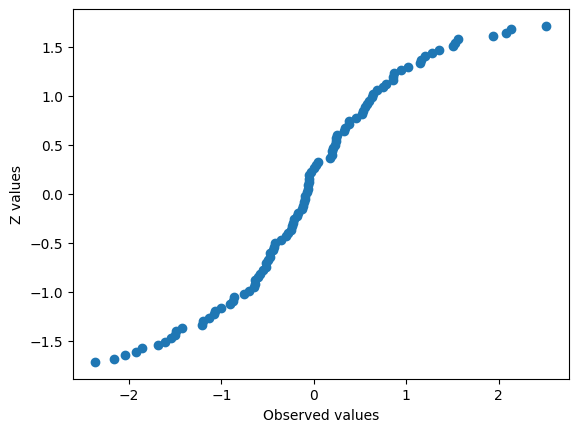

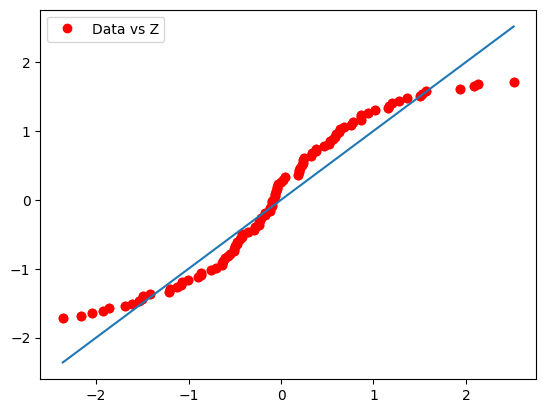

In [1]:
from scipy.stats import zscore
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
#its just an example npp of original values v/s theortical values(z scores)
def npp(data):
    data = sorted(data)
    p = [(data.index(i)-0.5)/len(data) for i in data]
    z = zscore(p)

  # Plot scatter plot of observed values vs Z-values
    plt.scatter(data, z)
    plt.ylabel('Z values')
    plt.xlabel('Observed values')
    plt.show()
  # Plot same data using red dots and add legend
    plt.plot(data, z, 'ro', label='Data vs Z')
    plt.legend()
  # Plot line of best fit
    plt.plot(data,  z,'ro',data,  data)
    plt.show()

#n datapoints
n = 100
data = np.random.randn(n)
npp(data)

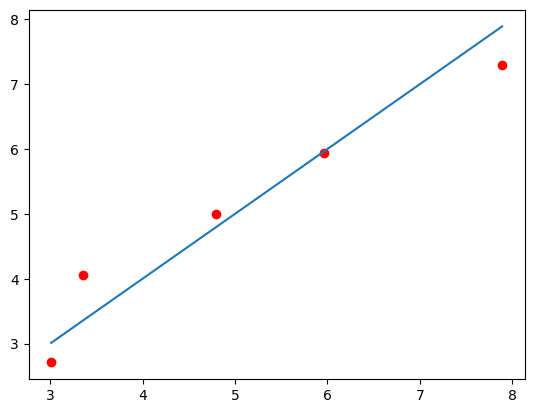

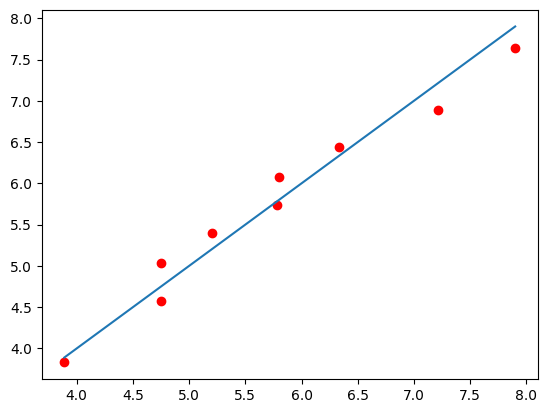

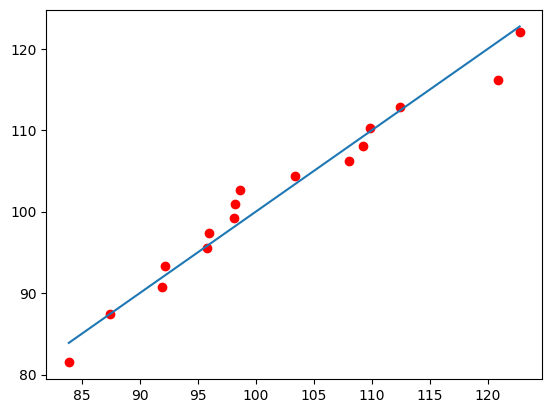

In [2]:

X1 = [3.01, 3.35, 4.79, 5.96, 7.89]

X2 = [3.89, 4.75, 4.75, 5.20, 5.78, 5.80, 6.33, 7.21, 7.90]

X3 = [108.047, 109.249, 103.385, 112.454, 95.780,  122.734, 109.842 , 120.858,
      98.604, 98.122,  95.971, 98.173,   87.437 , 91.884, 92.193,  83.882]
def npp1(data):

    p =[]   # Initialize list for cumulative probabilities (percentiles)
    t =[]   # Initialize list for theoretical quantiles

    data = np.sort(np.array(data))   # Sorting is essential for quantile comparison

    p = [(i - 0.5)/len(data) for i in range(1, len(data)+1)]   # Calculate plotting positions


    t = [norm.ppf(i, np.mean(data), np.std(data)) for i in p] #Computes the theoretical quantiles based on the normal distribution with mean and standard deviation calculated from the data. norm.ppf is the Percent-Point Function
    plt.plot(data, t, 'ro', data, data)
    plt.show()

npp1(X1)
npp1(X2)
npp1(X3)

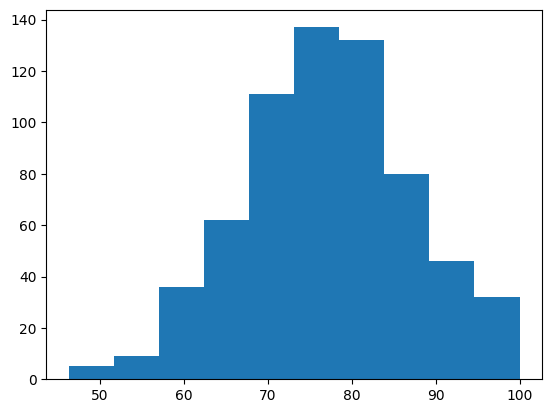

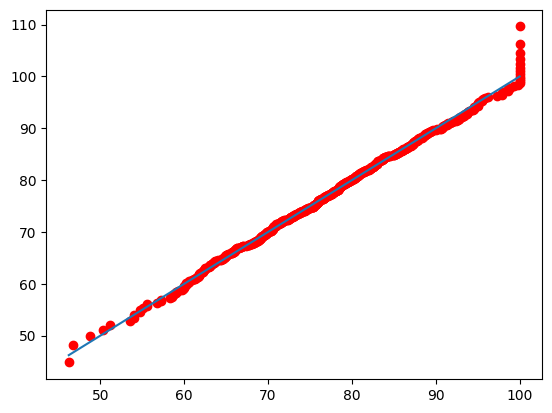

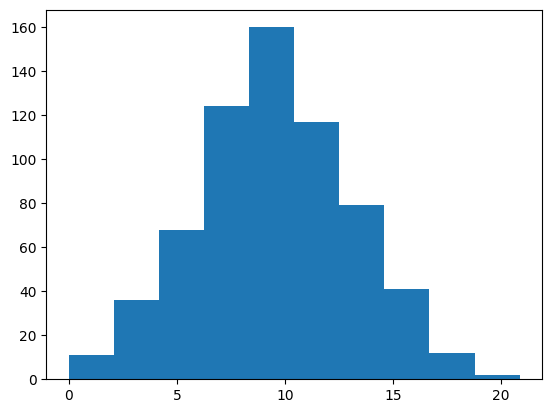

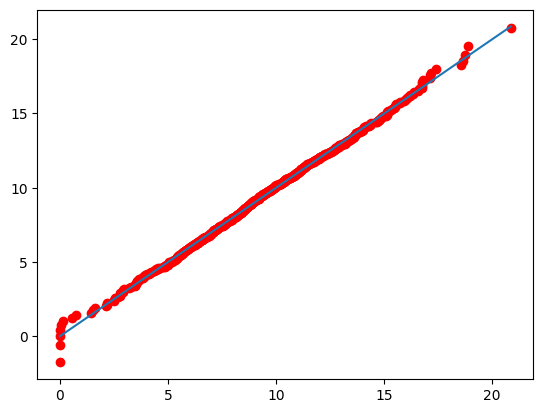

In [8]:
import pandas as pd

df = pd.read_csv('/content/Dataset_NPP.csv')
plt.hist(df.Attendance)
plt.show()
npp1(df.Attendance)


plt.hist(df.Study_Hours)
plt.show()
npp1(df.Study_Hours)

In [10]:
import csv
import pandas as pd
from random import sample

df = pd.read_csv('/content/Dataset_sampling.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 352 entries, 0 to 351
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Student_ID         350 non-null    object 
 1   Department         350 non-null    object 
 2   Gender             350 non-null    object 
 3   Age                350 non-null    float64
 4   GPA                350 non-null    float64
 5   Credits_Completed  350 non-null    float64
 6   Attendance         350 non-null    float64
 7   Scholarship        350 non-null    object 
dtypes: float64(4), object(4)
memory usage: 22.1+ KB


In [11]:
#simple random sampling
no_of_elements = 10
random_index = sample(range(df.shape[0]), no_of_elements)
print(random_index)
print(df.iloc[random_index])

[35, 339, 245, 62, 289, 236, 210, 252, 138, 184]
    Student_ID Department  Gender   Age   GPA  Credits_Completed  Attendance  \
35       S1168        CSE  Female  24.0  8.75              140.0       59.68   
339      S1238        EEE    Male  20.0  5.66              112.0       70.66   
245      S1347        CSE    Male  19.0  6.97              111.0      120.00   
62       S1060        ECE    Male  21.0  8.37              140.0       92.15   
289      S1248         CE  Female  18.0  6.58               88.0       95.17   
236      S1305         CE    Male  23.0  7.02              105.0       82.58   
210      S1303        EEE    Male  19.0  7.19              140.0      100.00   
252      S1158        CSE    Male  21.0  6.93              117.0       53.56   
138      S1304         ME  Female  19.0  7.72              140.0       69.91   
184      S1030         ME  Female  18.0  7.43              140.0       65.19   

    Scholarship  
35           No  
339          No  
245          No 

In [12]:
#systematic sampling
Kth = 100
index = [i for i in range(df.shape[0]) if i%Kth==0]
print(df.iloc[index])

    Student_ID Department  Gender   Age    GPA  Credits_Completed  Attendance  \
0        S1152        CSE  Female  20.0  10.00              140.0       65.54   
100      S1254        CSE    Male  19.0   7.99              140.0       61.27   
200      S1010         CE    Male  23.0   7.26              140.0       61.43   
300      S1292        CSE  Female  20.0   6.42               44.0       72.00   

    Scholarship  
0            No  
100          No  
200         Yes  
300          No  


In [13]:
#stratified sampling
#stratas formed based on Department
no_of_elements = 4        #number of elements in each strata
unique = list(set(df['Department']))
print('stratas :', unique, '\n')
index_set = [sample(list(df.index[df['Department']==i]), no_of_elements) for i in unique]
index = [j for i in index_set for j in i]
print(df.iloc[index])

stratas : ['ECE', 'EEE', nan, 'CSE', 'ME', 'CE'] 



ValueError: Sample larger than population or is negative

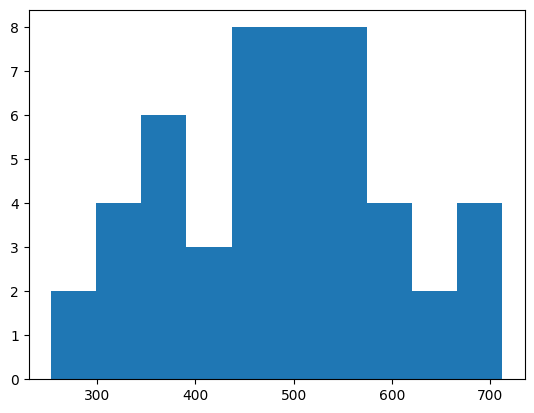

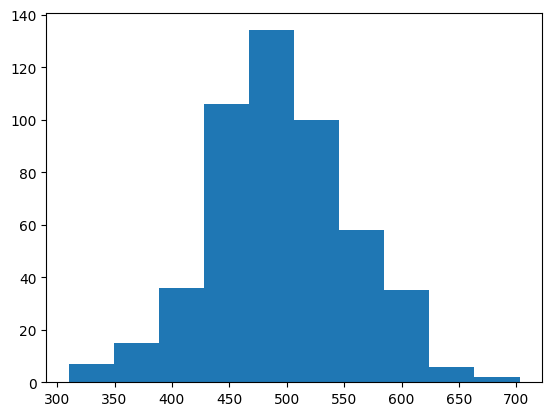

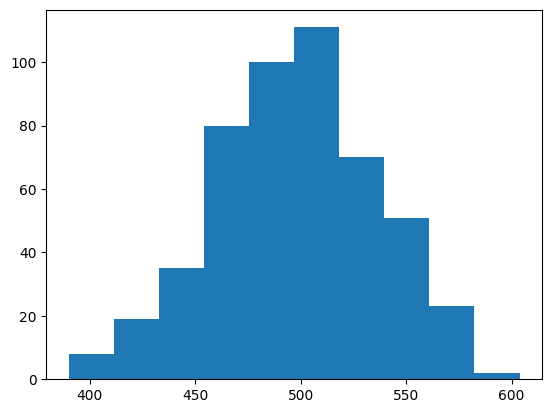

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from random import sample
from statistics import mean

def plot(arr, N, n_samples):
    x = []
    for i in range(1, n_samples):
        #to find N samples from the arr
        smp = sample(arr, N)
        mu = mean(smp)
        x.append(mu)
    plt.hist(x)
    plt.show()

#example data(population)
arr = [i for i in range(1000)]

#variations
plot(arr, 5, 50)
plot(arr, 20, 500)
plot(arr, 50, 500)
#so as number of samples(n_sample) increases the distribution becomes normal
#so as sample size increases the flatness of the distribution decreses

In [16]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful